<a href="https://colab.research.google.com/github/dldustj0715/machine_learning/blob/main/week08/mobile_price_classification_dl.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Mobile Price Range — 딥러닝 다중 분류

**Sequential / Dense / ReLU / Softmax / categorical_crossentropy**를 사용하여 휴대전화 사양으로 `price_range`(0~3)를 분류한다.

## 1. Google Drive 연결 및 라이브러리

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

tf.keras.utils.set_random_seed(42)

Mounted at /content/drive


## 2. CSV 불러오기 및 확인

In [2]:
path = '/content/drive/MyDrive/Colab Notebooks/mobile.csv'
df = pd.read_csv(path)
display(df.head())
print('데이터 크기:', df.shape)
print('결측치 합계:', df.isna().sum().sum())
print('가격 등급별 데이터 수:')
print(df['price_range'].value_counts().sort_index())

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,...,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,...,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,...,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0,0,0,10,0.8,131,6,...,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.2,0,13,1,44,0.6,141,2,...,1208,1212,1411,8,2,15,1,1,0,1


데이터 크기: (2000, 21)
결측치 합계: 0
가격 등급별 데이터 수:
price_range
0    500
1    500
2    500
3    500
Name: count, dtype: int64


## 3. 입력(X)과 정답(y) 분리

`price_range`는 예측 대상이므로 입력에서 제외한다. 정답은 원핫 인코딩해  `categorical_crossentropy`를 사용한다.

In [3]:
X = df.drop(columns=['price_range']).values.astype('float32')
y = df['price_range'].values.astype('int32')
print('입력:', X.shape, '정답:', y.shape, '클래스:', np.unique(y))
assert np.array_equal(np.unique(y), np.arange(4)), 'price_range 레이블을 확인하세요.'

입력: (2000, 20) 정답: (2000,) 클래스: [0 1 2 3]


## 4. 학습/테스트 분리 및 표준화

데이터 누수를 방지하기 위해 학습 데이터에만 `fit_transform()`을 적용한다.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train).astype('float32')
X_test = scaler.transform(X_test).astype('float32')

# 원-핫 인코딩 (4개 가격 등급)
Y_train = tf.keras.utils.to_categorical(y_train, num_classes=4)
Y_test = tf.keras.utils.to_categorical(y_test, num_classes=4)
print('학습 입력:', X_train.shape, '학습 정답:', Y_train.shape)
print('테스트 입력:', X_test.shape, '테스트 정답:', Y_test.shape)

학습 입력: (1600, 20) 학습 정답: (1600, 4)
테스트 입력: (400, 20) 테스트 정답: (400, 4)


## 5. 딥러닝 모델 생성

20개 입력 특성 → Dense(32, ReLU) → Dense(16, ReLU) → Dense(4, Softmax)

In [5]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(20,)),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dense(4, activation='softmax')
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │            68 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,268 (4.95 KB)

 Trainable params: 1,268 (4.95 KB)

 Non-trainable params: 0 (0.00 B)

## 6. 모델 컴파일 및 학습

In [6]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    X_train, Y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 4s 35ms/step - accuracy: 0.2562 - loss: 1.4615 - val_accuracy: 0.2906 - val_loss: 1.3768
Epoch 2/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.3320 - loss: 1.3237 - val_accuracy: 0.3625 - val_loss: 1.2991
Epoch 3/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.4336 - loss: 1.2162 - val_accuracy: 0.4406 - val_loss: 1.2013
Epoch 4/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.5383 - loss: 1.0867 - val_accuracy: 0.5437 - val_loss: 1.0747
Epoch 5/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.6172 - loss: 0.9487 - val_accuracy: 0.6187 - val_loss: 0.9509
Epoch 6/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.6680 - loss: 0.8281 - val_accuracy: 0.6406 - val_loss: 0.8460
Epoch 7/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.7305 - loss: 0.7298 - val_accuracy: 0.6687 - val_loss: 0.7594
Epoch 8/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.7695 - loss: 0.6481 - val_accuracy: 0.71

## 7. 테스트 데이터 평가

In [7]:
test_loss, test_accuracy = model.evaluate(X_test, Y_test, verbose=0)
print(f'Test Loss: {test_loss:.4f}')
print(f'Test Accuracy: {test_accuracy:.4f}')

Test Loss: 0.2559
Test Accuracy: 0.9175


## 8. 학습 정확도와 손실 시각화

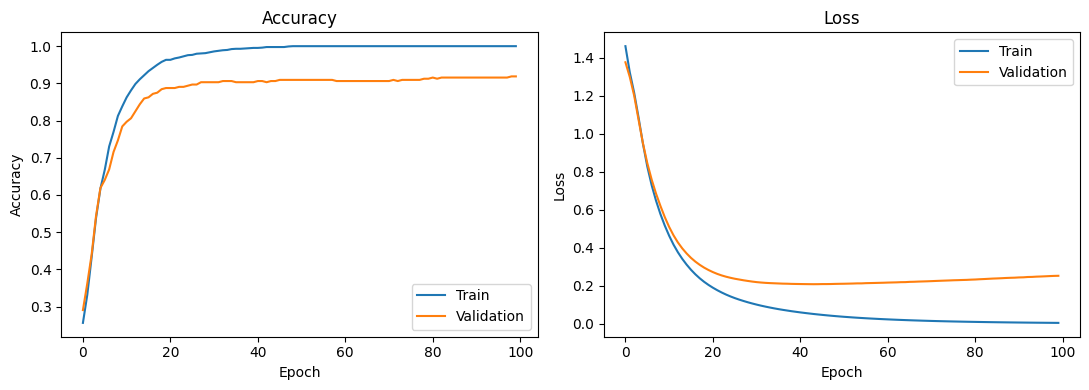

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(history.history['accuracy'], label='Train')
axes[0].plot(history.history['val_accuracy'], label='Validation')
axes[0].set(title='Accuracy', xlabel='Epoch', ylabel='Accuracy')
axes[0].legend()
axes[1].plot(history.history['loss'], label='Train')
axes[1].plot(history.history['val_loss'], label='Validation')
axes[1].set(title='Loss', xlabel='Epoch', ylabel='Loss')
axes[1].legend()
plt.tight_layout()
plt.show()

## 9. 가격 등급 예측 및 혼동행렬

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
              precision    recall  f1-score   support

           0       0.94      0.95      0.95       100
           1       0.88      0.89      0.89       100
           2       0.90      0.88      0.89       100
           3       0.95      0.95      0.95       100

    accuracy                           0.92       400
   macro avg       0.92      0.92      0.92       400
weighted avg       0.92      0.92      0.92       400



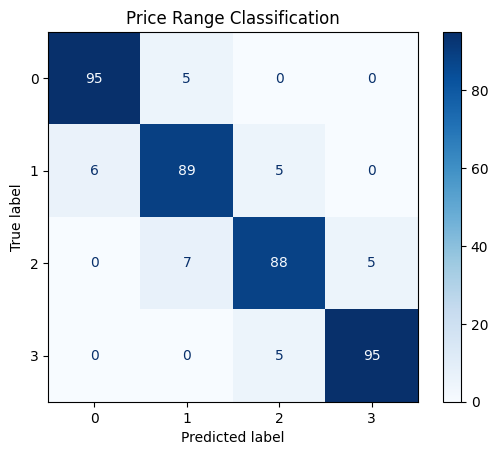

,Actual,Predicted
0,3,3
1,1,1
2,0,0
3,2,2
4,3,3
5,2,2
6,0,0
7,0,0
8,1,1
9,0,0


In [9]:
y_prob = model.predict(X_test)
y_pred = np.argmax(y_prob, axis=1)

print(classification_report(y_test, y_pred, labels=[0, 1, 2, 3], zero_division=0))
cm = confusion_matrix(y_test, y_pred, labels=[0, 1, 2, 3])
ConfusionMatrixDisplay(cm, display_labels=[0, 1, 2, 3]).plot(cmap='Blues')
plt.title('Price Range Classification')
plt.show()

results = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred})
display(results.head(10))

### 실습 정리
- 4개 가격 등급 중 하나를 예측
- 원핫 인코딩 적용
- `softmax` + `categorical_crossentropy` 사용